The goal of this notebook is to create descriptive annotations that are shorter than the ABC-like labels for neuronal clusters

In [1]:
from pathlib import Path
import re
import os 

import pandas as pd
import numpy as np
import scanpy as sc 

from dotenv import dotenv_values
from matplotlib import pyplot as plt
import seaborn as sns 

from hm3d_utils.statistics import find_markers
from hm3d_utils.utils import get_clusters_in_region

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

# markers
CLUSTERING_DIR = DATADIR / "5_clustering"
MARKERS_FP = CLUSTERING_DIR / 'HypoMap3D_marker_genes_qc.csv'
REGION_MARKERS_DIR = DATADIR / "8_annotation" / "region_specific_markers"

# adata
ADATA_FP = DATADIR / "6_NC_projection" / "all_integrated" / "HypoMap3D_full.h5ad"

# regions
REGIONS_ALL_FP = DATADIR / "7_spatial" / "analyses" / "regionwise_rm_all_wo_root_or_fibers.csv"
REGIONS_HY_FP = DATADIR / "7_spatial" / "analyses" / "regionwise_rm_HY_wo_root_or_fibers.csv"

# out
OUTDIR = DATADIR / "8_annotation"
OUTFILE = OUTDIR / "n_cluster_tree.csv"

# abc-like 
ABC_ANNO_FP = OUTDIR / "abc_like_annotation.csv"

## Load data and preprocess

### abc-like annotation mapper

In [3]:
# load abc-like annotation and get mapper
abclike = pd.read_csv(ABC_ANNO_FP, index_col=0)
abclike_mapper = pd.melt(abclike)
abclike_mapper = abclike_mapper.drop_duplicates() 
abclike_mapper["clusterID"] = abclike_mapper.value.apply(lambda x: x.split(" ", maxsplit=1)[0])
abclike_mapper = abclike_mapper.rename(columns={"value":"abc_like"})
abclike_mapper = abclike_mapper.set_index("clusterID").to_dict()["abc_like"]
abclike_mapper["Gl1-1 Glut"] = "Gl1-1 Glut" # missing in mapper
abclike_mapper["Gb1-2 GABA"] = "Gb1-2 GABA"

### adata 

In [4]:
# load adata, map abc-like annotation
adata = sc.read_h5ad(ADATA_FP, backed="r")
adata = adata[(adata.obs.IsControl) & (~adata.obs.L1.str.contains("NN"))].to_memory()
adata.obs[abclike.columns] = abclike.loc[adata.obs.index, :]
adata.obs.L1_abc_like = adata.obs.L1_abc_like.map(abclike_mapper)# account for incorrect L1
sc.pp.normalize_total(adata, target_sum=10_000) # run markers operates on this

### gene metadata

In [5]:
gene_metadata = adata.var.reset_index()
gene_metadata = gene_metadata.rename(columns={"index": "Gene name", "gene_ids": "Gene stable ID"})
gene_metadata.head()

,Gene name,Gene stable ID,IsMouseTF,IsHumanTFOrtholog,IsSourceGene,IsTargetGene,IsHvgExcludedGene,IsAnnotationExcludedGene,IsPriorityGene,IsTopGene,IsHvg
0,Gm38212,ENSMUSG00000104478,False,False,False,False,False,True,False,False,False
1,Gm7449,ENSMUSG00000104385,False,False,False,False,False,True,False,False,False
2,Gm28283,ENSMUSG00000101231,False,False,False,False,False,True,False,False,False
3,Gm37108,ENSMUSG00000102135,False,False,False,False,False,True,False,False,False
4,Gm37275,ENSMUSG00000103282,False,False,False,False,False,True,False,False,False


In [6]:
further_exclude_mask = (
    gene_metadata["Gene name"].str.contains(r"Pde|Cntn|St18|C1q", regex=True, na=False)
    |
    gene_metadata["Gene name"].str.contains(r"\d+ot$", regex=True, na=False)
    |
    gene_metadata["Gene name"].str.contains(r"^[A-Z]{2}", regex=True, na=False)
)


In [7]:
gene_metadata.loc[further_exclude_mask, "IsAnnotationExcludedGene"] = True
gene_metadata.loc[further_exclude_mask, "IsPriorityGene"] = False
gene_metadata.loc[further_exclude_mask, "IsTopGene"] = False

In [8]:
source_genes_woTop = gene_metadata.loc[(gene_metadata.IsSourceGene) & (~gene_metadata.IsTopGene), "Gene name"].to_list()
target_genes_woTop = gene_metadata.loc[(gene_metadata.IsTargetGene) & (~gene_metadata.IsTopGene), "Gene name"].to_list()
tf_genes_woTop = gene_metadata.loc[((gene_metadata.IsMouseTF) | (gene_metadata.IsHumanTFOrtholog)) & (~gene_metadata.IsTopGene), "Gene name"].to_list()
top_genes = gene_metadata.loc[(gene_metadata.IsTopGene), "Gene name"].to_list()
exclude_genes = gene_metadata.loc[(gene_metadata.IsAnnotationExcludedGene), "Gene name"].to_list()

In [9]:
prio_top_genes = gene_metadata.loc[(gene_metadata.IsTopGene) | (gene_metadata.IsPriorityGene) , "Gene name"].to_list()

### marker genes

In [10]:
# load markers 
markers = pd.read_csv(MARKERS_FP)
markers = markers.loc[~markers.cluster.str.contains("NN"),:]
markers.cluster = markers.cluster.map(abclike_mapper)
assert markers.cluster.isna().sum() == 0, "NaN values in cluster column detected. something must be wrong with your mapping"  
markers.head()

,gene_name,direction,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,clustering,cluster,comparison
0,Foxb1,A,6.236570,0.106480,0.003613,0.576016,0.005636,6.674614,0.0,0.0,12.376232,22,L1,Gl1-1 Glut,OneVsSisters
1,Sim1,A,5.840800,0.230684,0.005491,0.649711,0.009302,6.125616,0.0,0.0,48.814749,8,L1,Gl1-1 Glut,OneVsSisters
2,Ebf3,A,5.403689,0.138809,0.005545,0.450222,0.007784,5.853412,0.0,0.0,27.623637,20,L1,Gl1-1 Glut,OneVsSisters
3,B230323A14Rik,A,5.163896,0.132151,0.005591,0.514981,0.010467,5.620158,0.0,0.0,16.798665,21,L1,Gl1-1 Glut,OneVsSisters
4,Pitx2,A,5.156033,0.150888,0.004613,0.334066,0.007476,5.481207,0.0,0.0,22.039370,19,L1,Gl1-1 Glut,OneVsSisters


### region predictions

In [11]:
# load region predictions and restrict to neuronal cell types of L3

all_regions = pd.read_csv(REGIONS_ALL_FP)
all_regions = all_regions.rename(columns={"Unnamed: 0": "cluster"})
all_regions = all_regions.loc[(all_regions.cluster.str[2] == "3") & (~all_regions.cluster.str.contains("NN"))]
all_regions.cluster = all_regions.cluster.map(abclike_mapper)
all_regions = all_regions.set_index("cluster").T.reset_index()
all_regions = all_regions.rename(columns={"index": "allen_acronym"})

hy_regions = pd.read_csv(REGIONS_HY_FP,)
hy_regions = hy_regions.rename(columns={"Unnamed: 0": "cluster"})
hy_regions = hy_regions.loc[(hy_regions.cluster.str[2] == "3") & (~hy_regions.cluster.str.contains("NN"))]
hy_regions.cluster = hy_regions.cluster.map(abclike_mapper)
hy_regions = hy_regions.set_index("cluster").T.reset_index()
hy_regions = hy_regions.rename(columns={"index": "allen_acronym"})
hy_acros = hy_regions.allen_acronym.unique()

# add an indicator for regions descending the HY acronym, i.e., are hypothalamic
all_regions["descends_HY"] = all_regions.allen_acronym.isin(hy_acros)

In [12]:
hy_regions.head()

cluster,allen_acronym,Gb3-124 SI-MPO-LPO Lhx8 GABA_2,Gb3-125 SI-MPO-LPO Lhx8 GABA_7,Gb3-126 SI-MPO-LPO Lhx8 GABA_4,Gb3-127 SI-MPO-LPO Lhx8 GABA_3,Gb3-128 SI-MPO-LPO Lhx8 GABA_8,Gb3-129 PVHd-DMH Lhx6 GABA_5,Gb3-130 PVHd-DMH Lhx6 GABA_3a,Gb3-131 PVHd-DMH Lhx6 GABA_3b,Gb3-132 PVHd-DMH Lhx6 GABA_2,...,Gl3-90 PMv-TMv Pitx2 Glut_4,Gl3-91 PMv-TMv Pitx2 Glut_3,Gl3-92 PMv-TMv Pitx2 Glut_5,Gl3-93 AHN-RCH-LHA Otp Fezf1 Glut_1,Gl3-94 AHN-RCH-LHA Otp Fezf1 Glut_3,Gl3-95 AHN-RCH-LHA Otp Fezf1 Glut_7,Gl3-96 AHN-RCH-LHA Otp Fezf1 Glut_2,Gl3-97 AHN-RCH-LHA Otp Fezf1 Glut_6,Gl3-98 VMH Nr5a1 Bcl11b Glut_2a,Gl3-99 VMH Nr5a1 Bcl11b Glut_2b
0,TMv,0.000900,0.000659,0.000900,0.000048,0.002453,0.003238,0.000369,0.000333,0.001053,...,0.003632,0.024087,0.026340,0.000111,0.000373,0.000668,0.000149,0.000520,0.003005,0.002566
1,PVa,0.000395,0.000126,0.000440,0.000172,0.000688,0.000084,0.000818,0.000217,0.000751,...,0.000105,0.000076,0.000053,0.000225,0.011845,0.020917,0.002182,0.000231,0.001066,0.003317
2,PVH,0.002389,0.000369,0.004007,0.002690,0.003445,0.000555,0.006055,0.004207,0.001955,...,0.002817,0.002577,0.001762,0.005839,0.036607,0.024116,0.008106,0.003548,0.001282,0.005515
3,PVHd,0.004537,0.001616,0.003330,0.001555,0.004668,0.016002,0.129767,0.051375,0.009468,...,0.002444,0.000696,0.000379,0.001812,0.017320,0.006881,0.003624,0.003951,0.000746,0.002944
4,ADP,0.048278,0.016957,0.097135,0.071287,0.013880,0.003674,0.011697,0.003348,0.012216,...,0.000031,0.000257,0.000490,0.000039,0.000658,0.002211,0.001326,0.000111,0.000091,0.000415


In [13]:
## sanity check that all clusters have predictions

# exclude 'allen_acronym' and any non-numeric columns
numeric_cols = hy_regions.select_dtypes(include='number').columns

non_pred_clusters = hy_regions[numeric_cols].columns[
    (hy_regions[numeric_cols].sum(axis=0) == 0)
].tolist()

assert len(non_pred_clusters) == 0, "there are clusters without predictions that require special treatment"

## Let's get the top region for each L3 cluster

For regional annotation, we divide clusters based on whether they may rather reflect hypothalamic or non-hypothalamic clusters based on the matching ABC labels:

If clusters match to ABC cell types with exclusively non-hypothalamic acronyms in their names, clusters likely reflect non-hypothalamic cell types.

For those cases, the regional annotation will be derived by allowing hypothalamic as well as non-hypothalamic brain regions as candidates for the region annotation, and the final top region will be determined solely based on relative mass.

Conversely, if HypoMap3D cell types map to ABC cell types that include hypothalamic brain regions, only hypothalamic brain regions will be allowed as possible candidates for the regional annotation if the relative mass within that hypothalamic brain region was at least 5%.

Hence, cell types will be separated into hy_clusters and non_hy_clusters in the following. 
 

In [14]:
hy_clusters = [] 
non_hy_clusters = []

for c in [col for col in hy_regions.columns[1:]]: #exclude the allen acronym column
    acros_in_c = c.split(" ")[1].split("-")
    if any([a in hy_acros for a in acros_in_c]):
        hy_clusters.append(c)
    else:
        non_hy_clusters.append(c)

In [15]:
len(hy_clusters), len(non_hy_clusters)

(212, 34)

Now, let's collect the relative masses for the top nuclei for the two cases:

1) allowing only hypothalamic acronyms 
2) allowing all acronyms 

Then, pick the top region based on the above decision rules.

In [16]:
excluded_nuclei = ["HY", "V3"] # do not annotate with these 


# initialize an empty list to collect results
top_rows = []

# combine both cluster lists
all_clusters = hy_clusters + non_hy_clusters

for cluster in all_clusters:

    df_subset_hy = all_regions[(all_regions["descends_HY"] == True) & ~(all_regions.allen_acronym.isin(excluded_nuclei))]
    df_subset_all = all_regions[~(all_regions.allen_acronym.isin(excluded_nuclei))]
    
    # get the row with the highest value for this cluster
    top_idx_hy = df_subset_hy[cluster].idxmax()
    top_alle_hy = df_subset_hy.loc[top_idx_hy, "allen_acronym"]
    top_relm_hy = df_subset_hy.loc[top_idx_hy, cluster]
    
    # get the row with the highest value for this cluster
    top_idx_all = df_subset_all[cluster].idxmax()
    top_alle_all = df_subset_all.loc[top_idx_all, "allen_acronym"]
    top_relm_all = df_subset_all.loc[top_idx_all, cluster]

    if cluster in non_hy_clusters:
        top_alle = top_alle_all
        top_relm = top_relm_all
    else: # use hy acros only (if that acro would have >= 5% relative mass)
        top_alle = top_alle_hy if top_relm_hy >= 0.05 else top_alle_all
        top_relm = top_relm_hy if top_relm_hy >= 0.05 else top_relm_all

    # store result as a dict
    top_rows.append({"top_region": top_alle, "cluster": cluster, "rel_mass":top_relm,
                        "top_region_all": top_alle_all, "rel_mass_all":top_relm_all,
                        "top_region_hy": top_alle_hy, "rel_mass_hy":top_relm_hy,})

# create the final DataFrame
top_l3_regions = pd.DataFrame(top_rows)


In [17]:
top_l3_regions.head()

,top_region,cluster,rel_mass,top_region_all,rel_mass_all,top_region_hy,rel_mass_hy
0,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2,0.131038,MPO,0.131038,MPO,0.131038
1,SI,Gb3-125 SI-MPO-LPO Lhx8 GABA_7,0.225381,SI,0.225381,LPO,0.029262
2,MPO,Gb3-126 SI-MPO-LPO Lhx8 GABA_4,0.063479,SI,0.093923,MPO,0.063479
3,MPO,Gb3-127 SI-MPO-LPO Lhx8 GABA_3,0.140100,MPO,0.140100,MPO,0.140100
4,SI,Gb3-128 SI-MPO-LPO Lhx8 GABA_8,0.118793,SI,0.118793,ZI,0.023503


## Let's get region-specific markers

While region-specific markers will be calculated in later steps of the pipeline, that calculation does not assign clusters to regions based on the decision rule above.
Hence, some clusters whose top region was selected from the HY-only regions may have been missing during that analysis.  

Hence, region-specific markers have to be calculated here while ensuring that those clusters are included as well.

These region-specific markers will later be used for L3 annotation.

In [18]:
# for reference, these are the clusters that received HY regions as their top region 
# despite having higher relative mass in non-HY regions when allowing all regions as candidates.
# top_l3_regions[top_l3_regions.top_region != top_l3_regions.top_region_all]

### Let's build a database for which clusters are found within region.

In [19]:
# input for get_clusters_in_region function 
all_regions_long = all_regions.loc[
    :, [c for c in all_regions.columns if c != "descends_HY"]
].melt(
    id_vars="allen_acronym",
    var_name="cluster",
    value_name="relative_mass"
).rename(columns={"allen_acronym": "acronym",})

In [20]:
cluster_in_region_dict = {}

for top_r in top_l3_regions.top_region.unique():

    # Get clusters based on relative mass alone
    cluster_df = get_clusters_in_region(all_regions_long, acronym=top_r, 
        top_k=5, min_rel_mass=0.1, cum_mass_max=0.6,
        cum_mass_mode="excluding",)
    preassigned = set(cluster_df.cluster.unique())

    # Ensure all clusters having their top_region there are included
    top_clusters = set(top_l3_regions.loc[top_l3_regions.top_region == top_r, "cluster"].unique())

    cluster_in_region_dict[top_r] = list(preassigned.union(top_clusters))

### Let's calculate region-specific markers

In cases there is only one cluster in a region, no region-specific marker genes can be calculated. 

For those clusters, global marker genes will be added instead.

In [21]:
rs_markers_outpath = REGION_MARKERS_DIR / "region_specific_markers_for_L3_annotation.csv"

In [22]:

if not os.path.exists(rs_markers_outpath): # dont'recalculate if file already exists:

    rs_markers_dfs = []
    global_clusters = []

    for top_r in top_l3_regions.top_region.unique():

        top_clusters_in_region = top_l3_regions.loc[top_l3_regions.top_region == top_r, "cluster"].unique() # only calculate markers for these vs other cluster in that region

        if len(top_clusters_in_region) < 2:
            global_clusters.extend(top_clusters_in_region) # we will add global genes later
        else:
            for tc in top_clusters_in_region:

                # get masks
                all_clusters_in_region = cluster_in_region_dict[top_r]
                other_clusters_in_region = [c for c in all_clusters_in_region if c != tc]

                self_mask = adata.obs["L3_abc_like"] == tc
                others_mask = adata.obs["L3_abc_like"].isin(other_clusters_in_region)
                
                markers_df = find_markers(
                    adata_A=adata[self_mask],
                    adata_B=adata[others_mask],
                    strata_key="Sample",
                    max_stratum_size=10_000,
                    min_stratum_size=10,
                    min_pct_expression=0.1,
                    min_specificity=0.1,
                ).reset_index(names = "gene_name")

                # filter
                markers_df = markers_df.loc[(markers_df.direction == "A") & (
                    markers_df.log2FC > 0) & (markers_df.padj < 0.05
                ), [c for c in markers_df.columns if c != "direction"]]

                # add metadata
                markers_df["region"] = top_r
                markers_df["cluster"] = tc

                rs_markers_dfs.append(markers_df)

    rs_markers = pd.concat(rs_markers_dfs, axis=0)
    del rs_markers_dfs

    # add global genes 
    gl_substitutes = markers.loc[(markers.cluster.isin(global_clusters)) & (markers.direction == "A") & (
                    markers.log2FC > 0) & (markers.padj < 0.05
                ) & (markers.comparison == "OneVsAll"), :]
    gl_subtitutes = gl_substitutes.drop(columns=["direction", "clustering", "comparison"])
    gl_substitutes["region"] = "global"
    gl_substitutes = gl_substitutes.loc[:, rs_markers.columns]

    rs_markers = pd.concat([rs_markers, gl_substitutes], axis=0)

    # save 
    rs_markers.to_csv(rs_markers_outpath ,index=False)

else: 
    rs_markers = pd.read_csv(rs_markers_outpath)
    rs_markers.cluster = rs_markers.cluster.apply(lambda x: abclike_mapper[x.split(" ")[0]])
    global_clusters = list(rs_markers.loc[rs_markers.region == "global", "cluster"].unique())


In [23]:
rs_markers.head()

,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,region,cluster
0,Meis1,5.588238,0.502935,0.017242,2.039954,0.032183,5.985010,0.0,0.0,26.075135,1,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2
1,Lmo3,2.812396,0.607449,0.087928,2.345005,0.172554,3.764375,0.0,0.0,26.837997,3,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2
2,Crh,2.877016,0.314221,0.032234,1.219915,0.105250,3.534771,0.0,0.0,11.320625,8,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2
3,Gm10754,2.520813,0.347630,0.051952,1.413362,0.133268,3.406652,0.0,0.0,17.513496,10,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2
4,Zeb2,0.978870,0.693002,0.190960,3.428593,1.038244,1.723527,0.0,0.0,25.235918,13,MPO,Gb3-124 SI-MPO-LPO Lhx8 GABA_2


## Let's build databases for markers

In [24]:
# these will be used to prefilter the genes.
# later, where databases for each level are built, you can make these more stringent
padj_threshold = 0.05 
specificity_threshold = 0.1
min_pct_sister = 0.15

In [25]:
tree_structure = adata.obs[[f'L{i}_abc_like' for i in range(1,6)]].drop_duplicates()
tree_structure = tree_structure.sort_values([f'L{i}_abc_like' for i in range(1,5)])
tree_structure.columns = [f'L{i}' for i in range(1,6)]

# Build parent-child mapping for hierarchy from tree_structure
all_parents = []
for i in range(1, 5):  # Map L1→L2, L2→L3, L3→L4, L4→L5
    temp = tree_structure.iloc[:, [i - 1, i]].copy()
    temp.columns = ['parent', 'child']
    all_parents.append(temp)
all_parents_df = pd.concat(all_parents).drop_duplicates()

In [26]:

# Count children per parent
child_counts = (
    all_parents_df.groupby('parent')['child']
    .nunique()
    .reset_index(name='child_count')
)


In [27]:
child_counts[child_counts.child_count > 1]

,parent,child_count
0,Gb1-2 GABA,30
1,Gb2-39 SI-MPO-LPO Lhx8 GABA,5
2,Gb2-40 PVHd-DMH Lhx6 GABA,4
3,Gb2-41 ZI Pax6 Pou6f2 GABA,6
4,Gb2-42 RT-ZI Gnb3 GABA,4
...,...,...
968,Gl4-83 PH-SUM Foxa1 Glut_9-1,2
971,Gl4-86 PH-SUM Foxa1 Glut_9-4,2
974,Gl4-89 PH-SUM Foxa1 Glut_9-7,2
977,Gl4-91 PH-SUM Foxa1 Glut_1-2,2


In [28]:

# --- 1. Children-sister markers ---
all_children_sister_markers = (
    markers
    .merge(all_parents_df, left_on='cluster', right_on='child')
    .merge(child_counts, left_on='parent', right_on='parent')
    .query(
        'specificity > @specificity_threshold and '
        'padj < @padj_threshold and '
        'comparison == "OneVsSisters" and '
        'child_count > 1'
    )
    .assign(is_children_sister=True)
    .rename(columns={"cluster": "child_cluster", 'parent': 'cluster', 'specificity': 'specificity_children_sister'})
    [['gene_name', 'cluster','is_children_sister', 'specificity_children_sister']]
    .drop_duplicates()
)

# Replace NA specificity with 0
all_children_sister_markers['specificity_children_sister'] = (
    all_children_sister_markers['specificity_children_sister'].fillna(0)
)


In [29]:

# Keep only the max specificity per (gene, cluster) if a gene is OvS in children multiple times
all_children_sister_markers = (
    all_children_sister_markers
    .sort_values('specificity_children_sister', ascending=False)
    .groupby(['gene_name', 'cluster'])
    .head(1)
)

In [30]:
# --- 2. Global markers ---
all_global_markers = (
    markers
    .query(
        'specificity > @specificity_threshold and '
        'padj < @padj_threshold and '
        'comparison == "OneVsAll"'
    )
    .assign(is_global=True)
    .rename(columns={'specificity': 'specificity_global'})
    [['gene_name', 'cluster', 'is_global', 'specificity_global']]
    .drop_duplicates()
)

In [31]:
all_global_markers.head()

,gene_name,cluster,is_global,specificity_global
371262,Foxb1,Gl1-1 Glut,True,6.236571
371263,Sim1,Gl1-1 Glut,True,5.840795
371264,Ebf3,Gl1-1 Glut,True,5.403687
371265,B230323A14Rik,Gl1-1 Glut,True,5.163895
371266,Pitx2,Gl1-1 Glut,True,5.156032


In [32]:
# --- 3. Sister markers ---
all_sister_markers = (
    markers
    .query(
        'specificity > @specificity_threshold and '
        'padj < @padj_threshold and '
        'comparison == "OneVsSisters"'
    )
    .assign(is_sister=True)
    .rename(columns={'specificity': 'specificity_sister'})
    [['gene_name', 'cluster', 'is_sister', 'specificity_sister']]
    .drop_duplicates()
)

In [33]:
all_sister_markers.head()

,gene_name,cluster,is_sister,specificity_sister
0,Foxb1,Gl1-1 Glut,True,6.236570
1,Sim1,Gl1-1 Glut,True,5.840800
2,Ebf3,Gl1-1 Glut,True,5.403689
3,B230323A14Rik,Gl1-1 Glut,True,5.163896
4,Pitx2,Gl1-1 Glut,True,5.156033


In [34]:

# For L3, merge into one database where the specificity and gene_name column are indiciating region markers. clusters without region markers will get global markers
pctB_threshold_region = 0.25 # only get genes that are in less than this pct of other clusters within the vicinity
min_marker_genes = 30

all_markers_all_filt = (
    rs_markers
    .query(
        'specificity > @specificity_threshold and '
        'padj < @padj_threshold'
    )
)
all_markers_all_filt["clustering"] = "L3"

# for the clusters where we have region specific markers, throw out all markers that have a max pctB
all_markers_all_filt = all_markers_all_filt.loc[~(
    (all_markers_all_filt.region != "global") & (all_markers_all_filt.pctB > pctB_threshold_region)
)]

# throw out genes to be excluded
all_markers_all_filt = all_markers_all_filt[
    ~all_markers_all_filt['gene_name'].isin(exclude_genes)
].copy()

# for clusters with too little nmber of markers, we add global markers

cluster_counts = all_markers_all_filt.groupby("cluster").size()

underfilled_clusters = cluster_counts[
    cluster_counts < min_marker_genes
].index.tolist()

if not len(underfilled_clusters) == 0:

    gl_substitutes = markers.loc[
        (markers.cluster.isin(underfilled_clusters))
        & (markers.direction == "A")
        & (markers.log2FC > 0)
        & (markers.padj < 0.05)
        & (~markers.gene_name.isin(exclude_genes))
        & (markers.comparison == "OneVsAll")
        & (markers.gene_name.isin(prio_top_genes)), #adding only priority or top genes from global genes
    ].copy()

    gl_substitutes = gl_substitutes.drop(
        columns=["direction", "clustering", "comparison"],
        errors="ignore"
    )

    gl_substitutes["region"] = "global"
    gl_substitutes["clustering"] = "L3"

    gl_substitutes = gl_substitutes.loc[:, all_markers_all_filt.columns]

    existing = set(
        zip(
            all_markers_all_filt["cluster"],
            all_markers_all_filt["gene_name"]
        )
    )

    gl_substitutes = gl_substitutes.loc[
        ~gl_substitutes.apply(
            lambda r: (r["cluster"], r["gene_name"]) in existing,
            axis=1
        )
    ]

    # supplement the markers with global markers up to min_marker_genes
    supplements = []

    for cluster in underfilled_clusters:

        current_n = cluster_counts.get(cluster, 0)
        needed = min_marker_genes - current_n

        candidates = (
            gl_substitutes
            .loc[gl_substitutes["cluster"] == cluster]
            .sort_values(
                ["specificity",],
                ascending=False
            )
            .head(needed)
        )

        supplements.append(candidates)

    supplements = pd.concat(supplements, ignore_index=True)

    all_markers_all_filt = pd.concat(
        [all_markers_all_filt, supplements],
        ignore_index=True
    )

all_markers_all_filt = (
    all_markers_all_filt
    .merge(top_l3_regions, on="cluster", how="left")
    .merge(all_sister_markers, on=["gene_name", "cluster"], how="left")
    .merge(all_children_sister_markers, on=["gene_name", "cluster"], how="left")
    .fillna(
        {
            "is_sister": False,
            "is_children_sister": False,
        }
    )
)

/tmp/ipykernel_3200279/856984294.py:100: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(


In [35]:
len(set(top_l3_regions.cluster.unique()) - set(all_markers_all_filt.cluster.unique()))

0

In [36]:

# For L4 and L5, merge into one database where the specificity and gene_name column are indicating sister markers
all_markers_sis_filt = (
    markers
    .query(
        'specificity > @specificity_threshold and '
        'padj < @padj_threshold and '
        'comparison == "OneVsSisters"'
    )
    #.merge(top_region, on='cluster', how='left')
    .merge(top_l3_regions, on='cluster', how='left')
    .merge(all_global_markers, on=['gene_name', 'cluster'], how='left')
    .merge(all_sister_markers, on=['gene_name', 'cluster'], how='left')
    .merge(all_children_sister_markers, on=['gene_name', 'cluster'], how='left')
    .fillna({'is_global': False, 'is_sister': False, 'is_children_sister': False})
)

/tmp/ipykernel_3200279/338841795.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna({'is_global': False, 'is_sister': False, 'is_children_sister': False})


In [37]:
all_markers_all_filt.head()

,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,...,top_region,rel_mass,top_region_all,rel_mass_all,top_region_hy,rel_mass_hy,is_sister,specificity_sister,is_children_sister,specificity_children_sister
0,Meis1,5.588238,0.502935,0.017242,2.039954,0.032183,5.985010,0.0,0.0,26.075135,...,MPO,0.131038,MPO,0.131038,MPO,0.131038,True,3.310093,True,0.267529
1,Lmo3,2.812396,0.607449,0.087928,2.345005,0.172554,3.764375,0.0,0.0,26.837997,...,MPO,0.131038,MPO,0.131038,MPO,0.131038,True,0.962713,True,0.213479
2,Crh,2.877016,0.314221,0.032234,1.219915,0.105250,3.534771,0.0,0.0,11.320625,...,MPO,0.131038,MPO,0.131038,MPO,0.131038,True,1.616706,True,0.204278
3,Zeb2,0.978870,0.693002,0.190960,3.428593,1.038244,1.723527,0.0,0.0,25.235918,...,MPO,0.131038,MPO,0.131038,MPO,0.131038,False,NaN,False,NaN
4,Kcnk13,2.076032,0.310835,0.052712,0.874538,0.115238,2.923926,0.0,0.0,14.131527,...,MPO,0.131038,MPO,0.131038,MPO,0.131038,True,1.053361,True,0.378966


## Let's process L2

For L2, we keep the abc-like annotation but shorten it a bit.

In [38]:

def rename_L2_clusters(tree_structure: pd.DataFrame) -> pd.DataFrame:

    # Select and filter
    df = (
        tree_structure[['L2', 'L3']]
        .copy()
        .loc[~tree_structure['L2'].str.contains("NN2-", na=False)] # remove NN if present
    )

    # Determine neurotransmitter type
    df['is_gaba'] = df['L2'].str.contains(r'\bGABA\b', regex=True)
    df['is_glut'] = df['L2'].str.contains(r'\bGlut\b', regex=True)

    # Remove GABA/Glut from the name to create base_name
    df['base_name'] = df['L2'].str.replace(r'\s*(GABA|Glut)\b', '', regex=True)

    # Separate base_name into components
    base_split = df['base_name'].str.split(r'\s+', n=4, expand=True)
    base_split.columns = ['cluster_id', 'region', 'gene1', 'gene2', 'gene3'][:base_split.shape[1]]

    # Ensure all expected columns exist
    for col in ['cluster_id', 'region', 'gene1', 'gene2', 'gene3']:
        if col not in base_split.columns:
            base_split[col] = np.nan

    df = pd.concat([df, base_split], axis=1)

    # Combine gene columns into one string
    df['gene_in_name'] = df[['gene1', 'gene2', 'gene3']].apply(
        lambda row: ".".join([x for x in row if pd.notna(x) and x != ""]),
        axis=1
    )

    # Create the trivial name (cluster_id + region + genes)
    df['cluster_trivial_L2'] = (
        df['cluster_id'].fillna('') + " " +
        df['region'].fillna('') + " " +
        df['gene_in_name']
    ).str.replace(r'\s+', ' ', regex=True).str.strip()

    # Drop duplicates and unnecessary columns
    df = (
        df.drop_duplicates(subset=['L2', 'L3'])
          .drop(columns=['gene_in_name', 'region', 'is_gaba', 'is_glut'])
          .reset_index(drop=True)
    )

    # Replace missing genes with empty strings
    for col in ['gene2', 'gene3']:
        if col in df.columns:
            df[col] = df[col].fillna('')

    return df


In [39]:
renamed_l2_clusters_both_short = rename_L2_clusters(tree_structure)
renamed_l2_clusters_both_short.loc[renamed_l2_clusters_both_short.cluster_trivial_L2.str.contains("Gb2-64"), "cluster_trivial_L2"] = "Gb2-64 TMv-PMv Tbx3" # remove .Hist- artifact

In [40]:
#sorted(list(renamed_l2_clusters_both_short.cluster_trivial_L2.unique()))

In [41]:
renamed_l2_clusters_both_short.head()

,L2,L3,base_name,cluster_id,gene1,gene2,gene3,cluster_trivial_L2
0,Gb2-39 SI-MPO-LPO Lhx8 GABA,Gb3-124 SI-MPO-LPO Lhx8 GABA_2,Gb2-39 SI-MPO-LPO Lhx8,Gb2-39,Lhx8,,,Gb2-39 SI-MPO-LPO Lhx8
1,Gb2-39 SI-MPO-LPO Lhx8 GABA,Gb3-125 SI-MPO-LPO Lhx8 GABA_7,Gb2-39 SI-MPO-LPO Lhx8,Gb2-39,Lhx8,,,Gb2-39 SI-MPO-LPO Lhx8
2,Gb2-39 SI-MPO-LPO Lhx8 GABA,Gb3-126 SI-MPO-LPO Lhx8 GABA_4,Gb2-39 SI-MPO-LPO Lhx8,Gb2-39,Lhx8,,,Gb2-39 SI-MPO-LPO Lhx8
3,Gb2-39 SI-MPO-LPO Lhx8 GABA,Gb3-127 SI-MPO-LPO Lhx8 GABA_3,Gb2-39 SI-MPO-LPO Lhx8,Gb2-39,Lhx8,,,Gb2-39 SI-MPO-LPO Lhx8
4,Gb2-39 SI-MPO-LPO Lhx8 GABA,Gb3-128 SI-MPO-LPO Lhx8 GABA_8,Gb2-39 SI-MPO-LPO Lhx8,Gb2-39,Lhx8,,,Gb2-39 SI-MPO-LPO Lhx8


## Let's process L3

In [42]:
def score_markers(
    df,
    level,
    source_genes_woTop,
    target_genes_woTop,
    tf_genes_woTop,
    top_genes,
    ligand_score=0.25,
    receptor_score=0.25,
    tf_score=0.25,
    top_gene_score=1,
    children_sister_penalty_factor=2,
    sister_boost_factor=0.5,
    global_boost_factor=0.5,
):
    """
    Score markers including ligand/receptor/TF bonuses
    and children-sister / sister / global adjustments.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe with marker info.
    level : str
        Level label (e.g., 'L3', 'L4', 'L5').
    source_genes_woTop, target_genes_woTop, tf_genes_woTop, top_genes : list-like
        Lists of gene names for each category (mandatory).
    ligand_score : float, default=0.25
        Bonus added if gene is a ligand.
    receptor_score : float, default=0.25
        Bonus added if gene is a receptor.
    tf_score : float, default=0.25
        Bonus added if gene is a transcription factor.
    top_gene_score : float, default=1
        Bonus added if gene is a top gene.
    children_sister_penalty_factor : float, default=2
        Multiplier for the children-sister penalty.
    sister_boost_factor : float, default=0.5
        Multiplier for sister boost (e.g., specificity_sister * 0.5).
    global_boost_factor : float, default=0.5
        Multiplier for global boost (e.g., specificity_global * 0.5).
    """

    # Convert to sets for faster lookup
    source_genes_woTop = set(source_genes_woTop)
    target_genes_woTop = set(target_genes_woTop)
    tf_genes_woTop = set(tf_genes_woTop)
    top_genes = set(top_genes)

    df['score'] = 1.0

    # Children-sister penalty for all but L5
    if 'is_children_sister' in df.columns and level not in ["L5"]:
        mask = df['is_children_sister'] == True
        df.loc[mask, 'score'] -= df.loc[mask, 'specificity_children_sister'] * children_sister_penalty_factor

    # Sister boost for L3
    if 'is_sister' in df.columns and level == "L3":
        mask = df['is_sister'] == True
        df.loc[mask, 'score'] += df.loc[mask, 'specificity_sister'] * sister_boost_factor

    # Global boost for levels L4/L5
    if 'is_global' in df.columns and level in ['L4', 'L5']:
        mask = df['is_global'] == True
        df.loc[mask, 'score'] += df.loc[mask, 'specificity_global'] * global_boost_factor

    # Add ligand/receptor/TF/top gene bonuses
    df.loc[df['gene_name'].isin(source_genes_woTop), 'score'] += ligand_score
    df.loc[df['gene_name'].isin(target_genes_woTop), 'score'] += receptor_score
    df.loc[df['gene_name'].isin(tf_genes_woTop), 'score'] += tf_score
    df.loc[df['gene_name'].isin(top_genes), 'score'] += top_gene_score

    # Multiply by specificity for final adjustment
    df['score'] *= df['specificity']
    df.loc[df['score'] == 0, 'score'] = 0.01

    return df


For L3, we filter the region specific marker genes iteratively, trying to extract at least 20 markers per cluster, starting at a pctA threshold of 0.5 and iteratively relaxing that criterium by 0.05 per iteration.

In [43]:

padj_threshold_l3 = 1e-4
specificity_threshold_l3 = 0.25

pctA_threshold_start = 0.5
pctA_threshold_step_size = 0.05
n_genes_min = 20


# Apply fixed filters once
candidate_genes = all_markers_all_filt.loc[
    (all_markers_all_filt["padj"] < padj_threshold_l3)
    & (all_markers_all_filt["specificity"] > specificity_threshold_l3)
].copy()

selected = pd.DataFrame(columns=candidate_genes.columns)

pctA_threshold = pctA_threshold_start

while pctA_threshold >= 0:

    # clusters that still need more genes
    current_counts = selected.groupby("cluster").size()

    underfilled = set(candidate_genes["cluster"]) - set(
        current_counts[current_counts >= n_genes_min].index
    )

    if len(underfilled) == 0:
        break

    # genes newly eligible at this threshold
    new_genes = candidate_genes.loc[
        (candidate_genes["cluster"].isin(underfilled))
        & (candidate_genes["pctA"] >= pctA_threshold)
    ]

    # add while avoiding duplicates
    selected = pd.concat([selected, new_genes], ignore_index=True)
    selected = selected.drop_duplicates(
        subset=["cluster", "gene_name"]  # adjust gene column name if needed
    )

    pctA_threshold -= pctA_threshold_step_size

L3_markers_all_filt = selected

/tmp/ipykernel_3200279/2215700331.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  selected = pd.concat([selected, new_genes], ignore_index=True)


In [44]:

# Left join on cluster names
L3_markers_all_filt = L3_markers_all_filt.merge(
    renamed_l2_clusters_both_short,
    left_on="cluster",
    right_on="L3",
    how="left"
)


In [45]:
len(set(top_l3_regions.cluster.unique()) - set(L3_markers_all_filt.cluster.unique()))

0

In [46]:
ligand_score=0.25
receptor_score=0.25
tf_score=0.25
top_gene_score=1


In [47]:
# Score
L3_markers_all_filt = score_markers(
    df = L3_markers_all_filt,
    level = "L3",
    source_genes_woTop = source_genes_woTop,
    target_genes_woTop = target_genes_woTop,
    tf_genes_woTop = tf_genes_woTop,
    top_genes = top_genes,
    ligand_score=ligand_score,
    receptor_score=receptor_score,
    tf_score=tf_score,
    top_gene_score=top_gene_score,
)

In [48]:
# filter

gene_filter_L3 = ["Tbx3", "Trh"] + top_genes

L3_markers_remaining = L3_markers_all_filt[
    ~L3_markers_all_filt['gene_name'].isin(exclude_genes)
].copy()

for col in ['gene1', 'gene2', 'gene3']:
    if col in L3_markers_remaining.columns:
        L3_markers_remaining = L3_markers_remaining[
            ~((L3_markers_remaining['gene_name'] == L3_markers_remaining[col]) & 
              (~L3_markers_remaining['gene_name'].isin(gene_filter_L3))) 
        ]

In [49]:
# check for missing clusters 

# All unique L3 clusters from the tree structure
all_l3_clusters = tree_structure['L3'].astype(str).unique()

# All unique clusters that have remaining markers
remaining_clusters = L3_markers_remaining['cluster'].astype(str).unique()

# Set difference: clusters in tree but not in remaining markers
missing_l3_clusters = set(all_l3_clusters) - set(remaining_clusters)

# Exclude clusters that start with "NN3-"
missing_l3_clusters = [c for c in missing_l3_clusters if not c.startswith("NN3-")]


print(len(missing_l3_clusters), missing_l3_clusters)

0 []


In [50]:

def iterative_rename_clusters(
    df,
    cluster_col,
    trivial_expr,
    level_name,
    max_iterations=10,
    extra_filters=None,
):
    """
    Generic iterative renaming function used by L3, L4, and L5:
    If genes would be assigned to clusters with the same region annotations, 
    the cluster with the higher score for that gene will get the gene.

    Parameters
    ----------
    df : pd.DataFrame
        Scored marker table
    cluster_col : str
        Column name of the cluster
    trivial_expr : function(row) -> str
        Function building the trivial cluster name for a row
    level_name : str
        Level label for progress messages (e.g., "L3")
    extra_filters : callable, optional
        Function that filters df between iterations

    Returns
    -------
    renamed_df : pd.DataFrame
    """
    renamed_all = pd.DataFrame()

    for i in range(max_iterations):
        print(f"Iteration {i+1} ({level_name})")

        if df.empty:
            break

        # Construct trivial cluster names dynamically
        df['cluster_trivial'] = df.apply(trivial_expr, axis=1)

        # Highest score per cluster
        top_per_cluster = (
            df.sort_values('score', ascending=False)
            .groupby(cluster_col, as_index=False)
            .head(1)
        )

        # Highest score per trivial name (avoid duplicates)
        top_per_trivial = (
            top_per_cluster.sort_values('score', ascending=False)
            .groupby('cluster_trivial', as_index=False)
            .head(1)
        )

        if top_per_trivial.empty:
            break

        renamed_all = pd.concat([renamed_all, top_per_trivial], ignore_index=True)

        # Remove used clusters / trivial names
        used_clusters = set(renamed_all[cluster_col])
        used_trivial = set(renamed_all['cluster_trivial'])
        df = df[
            ~df[cluster_col].isin(used_clusters) &
            ~df['cluster_trivial'].isin(used_trivial)
        ]

        # Optional external filtering (e.g., remove reused genes)
        if extra_filters:
            df = extra_filters(df, renamed_all)

        if len(renamed_all[cluster_col].unique()) == len(df[cluster_col].unique()):
            break

    return renamed_all.reset_index(drop=True)


In [51]:
# Define trivial_expr for L3
#trivial_expr = lambda row: f"{row['top_hy_region']} {row['gene_name']}"
ALLOW_L3_DUPLICATES = False


if ALLOW_L3_DUPLICATES:
    trivial_expr = lambda row: f"{row['L3'].split(' ')[0]} {row['top_region']} {row['gene_name']}"
else:
    trivial_expr = lambda row: f"{row['top_region']} {row['gene_name']}"


# Run iterative renaming on L3_markers_remaining
renamed_l3_clusters_all = iterative_rename_clusters(
    df=L3_markers_remaining,
    cluster_col='cluster',
    trivial_expr=trivial_expr,
    level_name='L3'
)

renamed_l3_clusters_all["IsPrioTop_L3"] = renamed_l3_clusters_all.gene_name.isin(prio_top_genes)

Iteration 1 (L3)
Iteration 2 (L3)
Iteration 3 (L3)


/tmp/ipykernel_3200279/1095025198.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['cluster_trivial'] = df.apply(trivial_expr, axis=1)


In [54]:
abc_to_prelim_l3 = adata.obs.loc[:, ["L3_prelim", "L3_abc_like"]].drop_duplicates().set_index("L3_abc_like").to_dict()["L3_prelim"]

In [55]:
renamed_l3_clusters_all["L3_prelim"] = renamed_l3_clusters_all.L3.map(abc_to_prelim_l3)

In [71]:
# Rename specific clusters manually
renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-228 "),
    'cluster_trivial'
] = "ARH Agrp"

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-144 "),
    'cluster_trivial'
] = "LHA Crh" # change away from LHA Nts

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-210 "),
    'cluster_trivial'
] = "DMH Ppp1r17" # change away from DMH Etv1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-232 "),
    'cluster_trivial'
] = "TMv Hdc" # change away from TMv Prph

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-233 "),
    'cluster_trivial'
] = "PMv Tcf7l2" # change away from PMv Npsr1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-245 "),
    'cluster_trivial'
] = "TU Pthlh" # change away from TU Ptk2b

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-101 "),
    'cluster_trivial'
] = "ARH Trhr" # change away from ARH Alk

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-102 "),
    'cluster_trivial'
] = "ARH Glipr1" # change away from ARH Unc5b

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-110 "),
    'cluster_trivial'
] = "VMH Col8a1" # change away from VMH Vegfc

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-114 "),
    'cluster_trivial'
] = "VMH Adamts9" # change away from VMH Sema3a

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-16 "),
    'cluster_trivial'
] = "PVH Ucn3" # change away from PVH Etv1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-18 "),
    'cluster_trivial'
] = "LHA Cartpt" # change away from LHA Tacr3

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-19 "),
    'cluster_trivial'
] = "LHA Ano1" # change away from LHA Shroom3

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-17 "),
    'cluster_trivial'
] = "LHA Oxtr" # change away from LHA Otx1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-2 "),
    'cluster_trivial'
] = "PVH-SO Oxt" # change away from PVH Galnt14

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-3 "),
    'cluster_trivial'
] = "PVH-SO Avp" # change away from TU th

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-4 "),
    'cluster_trivial'
] = "PVH-SO Pla2r1" # change away from PVH Pla2r1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-9 "),
    'cluster_trivial'
] = "LHA Htr1f" # change away from LHA Arhgap15

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-96 "),
    'cluster_trivial'
] = "AHN Tac1" # change away from AHN Slc17a6

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-87 "),
    'cluster_trivial'
] = "PVH Trh" # change away from PVH Nfix

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-83 "),
    'cluster_trivial'
] = "DMH Pdyn" # change away from DMH Tafa4

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-84 "),
    'cluster_trivial'
] = "DMH Nr2f1" # change away from DMH Pdyn

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-226 "),
    'cluster_trivial'
] = "SCH Cck" # change away from SCH Prokr2

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-235 "),
    'cluster_trivial'
] = "SCH Prokr2" # change away from SCH Itgb8

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-236 "),
    'cluster_trivial'
] = "SCH Avp" # change away from SCH Calcr

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-239 "),
    'cluster_trivial'
] = "SCH Vip" # change away from SCH Cd24a

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-1 "),
    'cluster_trivial'
] = "HY Gnrh1" # change away from VTA Gnrh1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-71 "),
    'cluster_trivial'
] = "MPN Synpr" # change away from MPN Sim1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-147 "),
    'cluster_trivial'
] = "LHA Gal" # change away from LHA Prox1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-171 "),
    'cluster_trivial'
] = "LHA Fign" # change away from LHA L3mbtl4

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-198 "),
    'cluster_trivial'
] = "AHN Sox6" # change away from AHN Cbln4

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gb3-211 "),
    'cluster_trivial'
] = "AHN Gpc4" # change away from AHN Sox6

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-107 "),
    'cluster_trivial'
] = "VMH Npffr1" # change away from VMH Lncenc1

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-13 "),
    'cluster_trivial'
] = "LHA Tmc4" # change away from LHA Tmc4

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-31 "),
    'cluster_trivial'
] = "PH Crhbp" # change away from PH Prdm8

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-75 "),
    'cluster_trivial'
] = "PVpo Trh" # change away from PVpo Six3 

renamed_l3_clusters_all.loc[
    renamed_l3_clusters_all['L3'].str.contains("Gl3-95 "),
    'cluster_trivial'
] = "AHN Col11a1" # change away from AHN Sim1


assert len(renamed_l3_clusters_all) ==  renamed_l3_clusters_all.cluster_trivial.nunique(), "clusters are not unique"
     


Let's rename a few for which we know better markers.

In [72]:
assert len(renamed_l3_clusters_all) ==  renamed_l3_clusters_all.cluster_trivial.nunique(), "clusters are not unique"

In [73]:
trivial_stem_mapper = renamed_l3_clusters_all.set_index("L3").to_dict()["cluster_trivial"] 
adata.obs["L3_trivial_stem"] = adata.obs.L3_abc_like.map(trivial_stem_mapper)

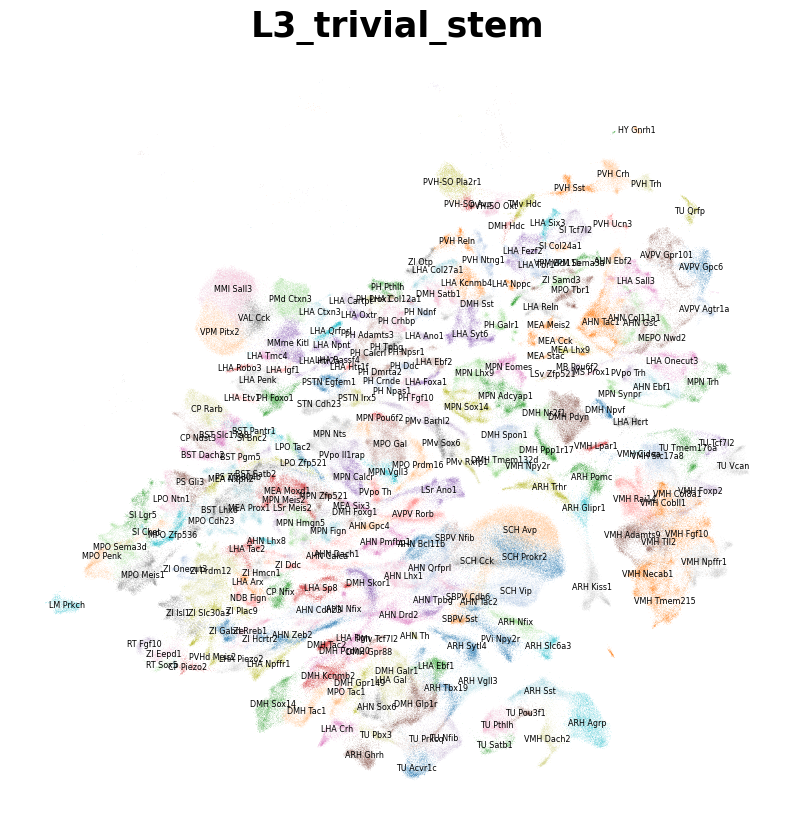

In [74]:
color = 'L3_trivial_stem'

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(10, 10), ) 

# Generate a large palette
n_categories = adata.obs[color].nunique()
palette = sns.color_palette("tab20", n_categories)  # or "husl", "tab10", "hsv", "Spectral"

# Randomize (shuffle) color order
rng = np.random.default_rng(seed=42)  # optional: set seed for reproducibility
palette = rng.permutation(palette).tolist()

# Pass the axis to Scanpy
sc.pl.umap(adata, color=color, ax=ax, show=False, legend_loc="on data", palette=palette, legend_fontsize = "xx-small", legend_fontweight="light",
    )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title(color, fontsize=25, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

fig.canvas.draw()

In [75]:

# Rename cluster_trivial to cluster_trivial_L3
renamed_l3_clusters_all = renamed_l3_clusters_all.rename(columns={'cluster_trivial': 'cluster_trivial_L3'})

# Select relevant columns for the "both_short" version
renamed_l3_clusters_both_short = renamed_l3_clusters_all[[
    'cluster', 'cluster_trivial_L3', 'cluster_trivial_L2', #'suffix'
]].copy()

# Merge with tree_structure on L3
renamed_l3_clusters_both_short = renamed_l3_clusters_both_short.merge(
    tree_structure,
    left_on='cluster',
    right_on='L3',
    how='left'
)

# Keep distinct rows per L4
renamed_l3_clusters_both_short = renamed_l3_clusters_both_short.drop_duplicates(
    subset=['L4']
)

# Drop L5 column if present
renamed_l3_clusters_both_short = renamed_l3_clusters_both_short.drop(columns=['L5'], errors='ignore')

## Let's process L4

In [76]:

# Filter columns 4:end (0-indexed in Python)
L4_markers_sis_filt = all_markers_sis_filt.copy()

# Filter for min_pct_sister
if 'pctA' in L4_markers_sis_filt.columns and min_pct_sister is not None:
    L4_markers_sis_filt = L4_markers_sis_filt[L4_markers_sis_filt['pctA'] >= min_pct_sister]

# Filter clustering "L4"
L4_markers_sis_filt = L4_markers_sis_filt[
    (L4_markers_sis_filt['clustering'] == "L4") 
].copy()

#print(L4_markers_sis_filt.cluster.nunique())

# Left join with L3 renamed clusters
L4_markers_sis_filt = L4_markers_sis_filt.merge(
    renamed_l3_clusters_both_short[['L4', 'cluster_trivial_L3', 'cluster_trivial_L2', #'suffix'
    ]],
    left_on='cluster',
    right_on='L4',
    how='left'
)

# Create gene_trivial_L3 by removing trailing letters
L4_markers_sis_filt['gene_trivial_L3'] = L4_markers_sis_filt['cluster_trivial_L3'].str.replace(r'^[a-zA-Z]+\s', '', regex=True)

# Drop the redundant L4 column from the merge
L4_markers_sis_filt = L4_markers_sis_filt.drop(columns=['L4'])

# Initialize L4_markers_remaining by filtering out excluded genes and trivial L3 genes
L4_markers_remaining = L4_markers_sis_filt[
    (~L4_markers_sis_filt['gene_name'].isin(exclude_genes)) &
    (L4_markers_sis_filt['gene_name'] != L4_markers_sis_filt['gene_trivial_L3'])
].copy()

# Score
L4_markers_remaining = score_markers(
    df = L4_markers_remaining,
    level = "L4",
    source_genes_woTop = source_genes_woTop,
    target_genes_woTop = target_genes_woTop,
    tf_genes_woTop = tf_genes_woTop,
    top_genes = top_genes,
)


In [77]:

# Define trivial_expr for L4
trivial_expr = lambda row: f"{row['cluster_trivial_L3']}.{row['gene_name']}"

# Run iterative renaming on L4_markers_remaining
renamed_l4_clusters_all = iterative_rename_clusters(
    df=L4_markers_remaining,
    cluster_col='cluster',
    trivial_expr=trivial_expr,
    level_name='L4'
)

renamed_l4_clusters_all = renamed_l4_clusters_all.rename(
    columns={'cluster_trivial': 'cluster_trivial_L4'}
)

# handle no sibling cases

# Count L4 clusters per L3 parent
l4_counts_per_L3 = renamed_l4_clusters_all.groupby('cluster_trivial_L3')['cluster'].nunique()

# Identify L3 parents with only one L4 child
single_child_parents = l4_counts_per_L3[l4_counts_per_L3 == 1].index

# L4 clusters whose parent has no siblings
l4_no_siblings = renamed_l4_clusters_all.loc[
    renamed_l4_clusters_all['cluster_trivial_L3'].isin(single_child_parents), 
    'cluster'
].tolist()

#print("L4 clusters with no siblings:", l4_no_siblings)

mask = renamed_l4_clusters_all['cluster'].isin(l4_no_siblings)
renamed_l4_clusters_all.loc[mask, 'cluster_trivial_L4'] = (
    renamed_l4_clusters_all.loc[mask, 'cluster_trivial_L4']
    .str.replace(r".[A-Za-z0-9]+$", "", regex=True)
)


Iteration 1 (L4)


Iteration 2 (L4)
Iteration 3 (L4)


/tmp/ipykernel_3200279/1095025198.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['cluster_trivial'] = df.apply(trivial_expr, axis=1)


In [78]:
# --- lost L4 clusters ---
lost_clusters = [c for c in tree_structure.loc[~tree_structure.L4.str.contains("NN"), "L4"].unique() 
                 if c not in L4_markers_remaining['cluster'].unique()]

len(lost_clusters)

0

In [79]:
# ensure all clusters are unique

assert renamed_l4_clusters_all.cluster.nunique() == renamed_l4_clusters_all.cluster_trivial_L4.nunique()

In [80]:
# ensure that all L4 clusters have a trivial name 

assert tree_structure.loc[~tree_structure.L4.str.contains("NN"), "L4"].nunique() == renamed_l4_clusters_all.cluster_trivial_L4.nunique()

In [81]:
abc_to_prelim_l4 = adata.obs.loc[:, ["L4_prelim", "L4_abc_like"]].drop_duplicates().set_index("L4_abc_like").to_dict()["L4_prelim"]
renamed_l4_clusters_all["L4_prelim"] = renamed_l4_clusters_all.cluster.map(abc_to_prelim_l4)

In [82]:
renamed_l4_clusters_both_short = renamed_l4_clusters_all[[
    'cluster', 'cluster_trivial_L4', 'cluster_trivial_L3', 'cluster_trivial_L2'
]].copy()

renamed_l4_clusters_both_short = renamed_l4_clusters_both_short.merge(
    tree_structure,
    left_on='cluster',
    right_on='L4',
    how='left'
)

renamed_l4_clusters_both_short = renamed_l4_clusters_both_short.drop_duplicates(
    subset=['L5']
)



## Let's process L5

In [83]:
# Filter columns 4:end (0-indexed)
L5_markers_sis_filt = all_markers_sis_filt.copy()

# Filter for min_pct_sister if pctA exists
if 'pctA' in L5_markers_sis_filt.columns and min_pct_sister is not None:
    L5_markers_sis_filt = L5_markers_sis_filt[L5_markers_sis_filt['pctA'] >= min_pct_sister]

# Filter for clustering "L5" 
L5_markers_sis_filt = L5_markers_sis_filt[
    (L5_markers_sis_filt['clustering'] == "L5")
].copy()

# Merge with renamed L4 clusters
L5_markers_sis_filt = L5_markers_sis_filt.merge(
    renamed_l4_clusters_both_short[['L5', 'cluster_trivial_L4', 'cluster_trivial_L3']],
    left_on='cluster',
    right_on='L5',
    how='left'
)

# Drop the redundant L5 column from the merge
L5_markers_sis_filt = L5_markers_sis_filt.drop(columns=['L5'])

def extract_parent_genes(trivial_str):
    """
    Given a string like 'SCH Vip.Mgat4c' or 'ZI Ebf2', returns list of genes.
    """
    if pd.isna(trivial_str):
        return []
    
    parts = trivial_str.split(maxsplit=1)  # split into region and rest
    if len(parts) < 2:
        return []
    
    gene_part = parts[1]  # second part contains gene(s)
    genes = gene_part.split('.')  # split by '/' if multiple genes
    genes = [g.strip() for g in genes if g]  # clean up whitespace and remove empty
    return genes

# Apply to L5 dataframe
L5_markers_sis_filt['parent_genes_L4'] = L5_markers_sis_filt['cluster_trivial_L4'].apply(extract_parent_genes)

# Filter out genes already used in L4 or excluded
L5_markers_remaining = L5_markers_sis_filt[
    (~L5_markers_sis_filt['gene_name'].isin(exclude_genes)) &
    (~L5_markers_sis_filt.apply(lambda row: row['gene_name'] in row['parent_genes_L4'], axis=1))
].copy()


# Score markers
L5_markers_remaining = score_markers(
    df=L5_markers_remaining,
    level="L5",
    source_genes_woTop=source_genes_woTop,
    target_genes_woTop=target_genes_woTop,
    tf_genes_woTop=tf_genes_woTop,
    top_genes=top_genes,
)



In [84]:

trivial_expr = lambda row: f"{row['cluster_trivial_L4']}.{row['gene_name']}"


renamed_l5_clusters_all = iterative_rename_clusters(
    df=L5_markers_remaining,
    cluster_col='cluster',
    trivial_expr=trivial_expr,
    level_name='L5'
)


# Rename cluster_trivial to cluster_trivial_L5
renamed_l5_clusters_all = renamed_l5_clusters_all.rename(columns={'cluster_trivial': 'cluster_trivial_L5'})

# --- Handle L5 clusters with no siblings ---

# Count L5 clusters per L4 parent
l5_counts_per_L4 = renamed_l5_clusters_all.groupby('cluster_trivial_L4')['cluster'].nunique()

# Identify L4 parents with only one L5 child
single_child_L4_parents = l5_counts_per_L4[l5_counts_per_L4 == 1].index

# L5 clusters whose L4 parent has no siblings
l5_no_siblings = renamed_l5_clusters_all.loc[
    renamed_l5_clusters_all['cluster_trivial_L4'].isin(single_child_L4_parents),
    'cluster'
].tolist()

# Adjust trivial names for L5 clusters with no siblings
mask = renamed_l5_clusters_all['cluster'].isin(l5_no_siblings)
renamed_l5_clusters_all.loc[mask, 'cluster_trivial_L5'] = (
    renamed_l5_clusters_all.loc[mask, 'cluster_trivial_L5']
    .str.replace(r".[A-Za-z0-9]+$", "", regex=True)
)

Iteration 1 (L5)
Iteration 2 (L5)


In [85]:
# ensure all clusters are unique

assert renamed_l5_clusters_all.cluster.nunique() == renamed_l5_clusters_all.cluster_trivial_L5.nunique()

# ensure that all L5 clusters have a trivial name 

assert tree_structure.loc[~tree_structure.L5.str.contains("NN"), "L5"].nunique() == renamed_l5_clusters_all.cluster_trivial_L5.nunique()

In [86]:
# Merge L2 info into renamed_l5_clusters_all via L3 trivial names
renamed_l5_clusters_all = renamed_l5_clusters_all.merge(
    renamed_l3_clusters_both_short[['cluster_trivial_L3', 'cluster_trivial_L2']],
    on='cluster_trivial_L3',
    how='left'
)

# Now create the "both_short" version
renamed_l5_clusters_both_short = renamed_l5_clusters_all[[
    'cluster', 
    'cluster_trivial_L5', 
    'cluster_trivial_L4', 
    'cluster_trivial_L3', 
    'cluster_trivial_L2',
]].copy()

# Merge with tree_structure on L5
renamed_l5_clusters_both_short = renamed_l5_clusters_both_short.merge(
    tree_structure,
    left_on='cluster',
    right_on='L5',
    how='left'
)

# Keep distinct rows per L5
renamed_l5_clusters_both_short = renamed_l5_clusters_both_short.drop_duplicates(
    subset=['L5']
)

## Let's add the prefixes and get a table combining all neuronal annotations

In [87]:
df = renamed_l5_clusters_both_short.copy()

In [88]:
for i in range(3,6):
    df[f'L{i}_trivial'] = df.apply(
    lambda row: row[f'L{i}'].split(" ", maxsplit=1)[0] + " " + row[f'cluster_trivial_L{i}'],
    axis=1
)

In [89]:
df["L1_trivial"] = df["L1"].copy()
df["L2_trivial"] = df["cluster_trivial_L2"].copy()

In [90]:
new_n_tree_structure = df.loc[:, [f"L{i}" for i in range(1,6)] + [f"L{i}_trivial" for i in range(1,6)]]
new_n_tree_structure.columns = [f"L{i}_abc_like" for i in range(1,6)] + [f"L{i}_descr" for i in range(1,6)]

for i in range(1,6):
    new_n_tree_structure[f"L{i}_ID"] = new_n_tree_structure[f"L{i}_abc_like"].apply(lambda x: x.split(" ")[0])

In [91]:
assert len(new_n_tree_structure) == len(tree_structure), "we lost a cluster somewhere"

In [92]:
for i in range(2,6):
    abc_to_prelim = adata.obs.loc[:, [f"L{i}_prelim", f"L{i}_abc_like"]].drop_duplicates().set_index(f"L{i}_abc_like").to_dict()[f"L{i}_prelim"]
    new_n_tree_structure[f"L{i}_prelim"] = new_n_tree_structure[f"L{i}_abc_like"].map(abc_to_prelim)

In [93]:
new_n_tree_structure.head()

,L1_abc_like,L2_abc_like,L3_abc_like,L4_abc_like,L5_abc_like,L1_descr,L2_descr,L3_descr,L4_descr,L5_descr,L1_ID,L2_ID,L3_ID,L4_ID,L5_ID,L2_prelim,L3_prelim,L4_prelim,L5_prelim
0,Gl1-1 Glut,Gl2-1 HY Gnrh1 Glut,Gl3-1 HY Gnrh1 Glut_1,Gl4-1 HY Gnrh1 Glut_1-1,Gl5-1 HY Gnrh1 Glut_1-1-1,Gl1-1 Glut,Gl2-1 HY Gnrh1,Gl3-1 HY Gnrh1,Gl4-1 HY Gnrh1,Gl5-1 HY Gnrh1,Gl1-1,Gl2-1,Gl3-1,Gl4-1,Gl5-1,Gl2-1 HY Gnrh1,Gl3-1 AVPV Gnrh1,Gl4-1 AVPV Gnrh1,Gl5-1 AVPV Gnrh1
1,Gl1-1 Glut,Gl2-13 MS-SF Bsx Glut,Gl3-35 MS-SF Bsx Glut_1a,Gl4-92 MS-SF Bsx Glut_1a-1,Gl5-122 MS-SF Bsx Glut_1a-1-1,Gl1-1 Glut,Gl2-13 MS-SF Bsx,Gl3-35 MS Prox1,Gl4-92 MS Prox1,Gl5-122 MS Prox1,Gl1-1,Gl2-13,Gl3-35,Gl4-92,Gl5-122,Gl2-13 MS-SF Bsx,Gl3-35 MS Onecut2,Gl4-92 MS Onecut2.Prox1,Gl5-122 MS Onecut2.Prox1
2,Gl1-1 Glut,Gl2-38 ARH-PVp Tbx3 Hmx2 Glut,Gl3-123 ARH-PVp Tbx3 Hmx2 Glut_4,Gl4-318 ARH-PVp Tbx3 Hmx2 Glut_4-1,Gl5-427 ARH-PVp Tbx3 Hmx2 Glut_4-1-1,Gl1-1 Glut,Gl2-38 ARH-PVp Tbx3.Hmx2,Gl3-123 VMH Lpar1,Gl4-318 VMH Lpar1,Gl5-427 VMH Lpar1,Gl1-1,Gl2-38,Gl3-123,Gl4-318,Gl5-427,Gl2-38 ARH-PVp Tbx3.Tnfsf11,Gl3-123 VMH Lpar1,Gl4-318 VMH Lpar1,Gl5-427 VMH Lpar1
3,Gl1-1 Glut,Gl2-26 DMH Nkx2-4 Glut,Gl3-83 DMH Nkx2-4 Glut_3,Gl4-204 DMH Nkx2-4 Glut_3-5,Gl5-280 DMH Nkx2-4 Glut_3-5-2,Gl1-1 Glut,Gl2-26 DMH Nkx2-4,Gl3-83 DMH Pdyn,Gl4-204 DMH Pdyn.Areg,Gl5-280 DMH Pdyn.Areg.Sprr1a,Gl1-1,Gl2-26,Gl3-83,Gl4-204,Gl5-280,Gl2-26 DMH Nkx2-4,Gl3-83 DMH Pdyn,Gl4-204 DMH Pdyn.Areg,Gl5-280 DMH Pdyn.Areg.Sprr1a
8,Gl1-1 Glut,Gl2-12 PH-SUM Foxa1 Glut,Gl3-34 PH-SUM Foxa1 Glut_1,Gl4-91 PH-SUM Foxa1 Glut_1-2,Gl5-120 PH-SUM Foxa1 Glut_1-2-1,Gl1-1 Glut,Gl2-12 PH-SUM Foxa1,Gl3-34 PH Prox1,Gl4-91 PH Prox1.Csgalnact1,Gl5-120 PH Prox1.Csgalnact1.Slc22a22,Gl1-1,Gl2-12,Gl3-34,Gl4-91,Gl5-120,Gl2-12 PH-SUM Foxa1,Gl3-34 PH C1ql1,Gl4-91 PH C1ql1.Zeb2-1,Gl5-120 PH C1ql1.Zeb2.Ndst4


In [104]:
new_n_tree_structure.to_csv(OUTFILE, index=False)